# Derive the closed-circuit pressure solve and valve check

Why can a pressure update conserve volume and still choose an impossible valve state?

Fall 2024.


## Predict
For the worked variable-compliance reduction, compute the closed candidate first. Does its conserved total imply that the closed valve is acceptable? Record the pressure inequality.

[{'assumed_open': False, 'pressure_mmHg': [24.0, 3.0], 'consistent': False}, {'assumed_open': True, 'pressure_mmHg': [14.666666666666666, 5.333333333333332], 'consistent': True}]


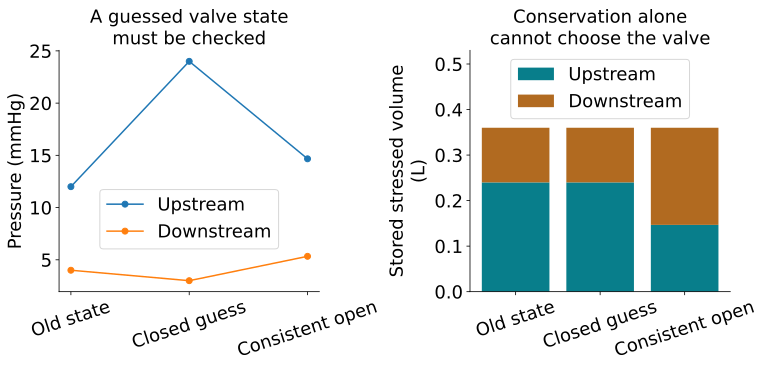

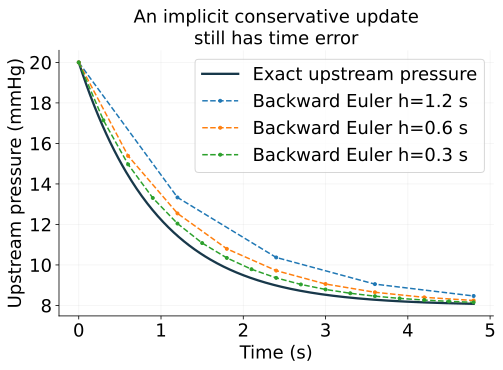

In [1]:
import demo
import numpy as np
from IPython.display import display, SVG
report=demo.run()
print(report['trace'])
display(SVG(filename='valve-trace.svg'))
display(SVG(filename='implicit-refinement.svg'))

## Implement (required)
Build the 2×2 matrix for the open candidate from the supplied new compliances and h/R. Replace `None`, solve, and check the known worked result. Then compute the two independent volume-balance residuals. This example is distinct from the assigned practice.

In [2]:
new_c=np.array([.01,.04]); old_amount=np.array([.24,.12]); h=.02; resistance=2.
learner_matrix=None  # new storage diagonal plus active link contribution
if learner_matrix is None:
    print('Required edit: assemble the open-valve matrix, then rerun.')
else:
    pressure=np.linalg.solve(learner_matrix,old_amount)
    assert np.max(np.abs(pressure-np.array([44/3,16/3])))<1e-11
    q=(pressure[0]-pressure[1])/resistance
    residual=(new_c*pressure-old_amount)/h-np.array([-q,q])
    assert q>=0 and np.max(np.abs(residual))<1e-10
    print('Known solve and both compartment balances pass.')

Required edit: assemble the open-valve matrix, then rerun.


## Modify and interpret
Start the same worked step with the open guess instead of the closed guess. Predict the final physical state and number of candidate solves. Then reverse the pressure ordering in a constant-compliance case; explain what the valve should do.

In [3]:
same=demo.implicit_step([12,4],[.02,.03],[.01,.04],.02,2,True)
blocked=demo.implicit_step([3,10],[.01,.04],[.01,.04],.01,2,True)
print('Open-start trace:',same['trace'])
print('Reverse-pressure flow:',blocked['flow_L_min'])

Open-start trace: [{'assumed_open': True, 'pressure_mmHg': [14.666666666666666, 5.333333333333332], 'consistent': True}]
Reverse-pressure flow: 0.0


## Explain
Give one example in which total conservation passes but another check fails. State which assumptions make the exponential reference valid, and identify the corresponding storage, conductance and valve checks in the six-compartment baseline.